# What do support, confidence and lift say across all 40,000 carts?

**Week 4, Wednesday, chapter 2 of 3.** Swiggy Instamart, Pune. Since Monday 7 September 2026 the
cart page's three-slot strip shows the items most often found in the same cart, and its
click-through fell from 6.1 percent to 3.8 percent. Illustrative case: the company is real, the situation and the data are synthetic, built for this class.
Chapter 1 counted twelve carts: bread to milk read confidence
1.00 and lift 1.50, chips and cold drink
lift 2.67. This notebook runs the same three counts on every cart.

**Who needs the answer.** The growth lead, who must say on Friday why the click-through
fell, and the category manager, who will defend milk because it is the top seller.

**The questions on the way.** How often is each item in a cart? Which pairs sit together
most often, and is that the ranking the strip should use? What does lift say about milk?
Why did the click-through fall?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations

carts = pd.read_csv("../data/C2_W04_D03_carts_STUDENT.csv")
items = pd.read_csv("../data/C2_W04_D03_cart_items_STUDENT.csv")
n = len(carts)
print(f"{n:,} carts from {carts.customer_id.nunique():,} customers, "
      f"{len(items):,} item lines, {items.item.nunique()} items")
check("40,000 carts", n == 40_000)
check("every item line belongs to a cart", items.cart_id.isin(carts.cart_id).all())

40,000 carts from 12,000 customers, 189,424 item lines, 59 items
PASS 40,000 carts
PASS every item line belongs to a cart


## How often is each item in a cart?

An item's support on its own is its share of carts. `cart_items` has one row per item in
a cart, so counting distinct carts per item gives it.

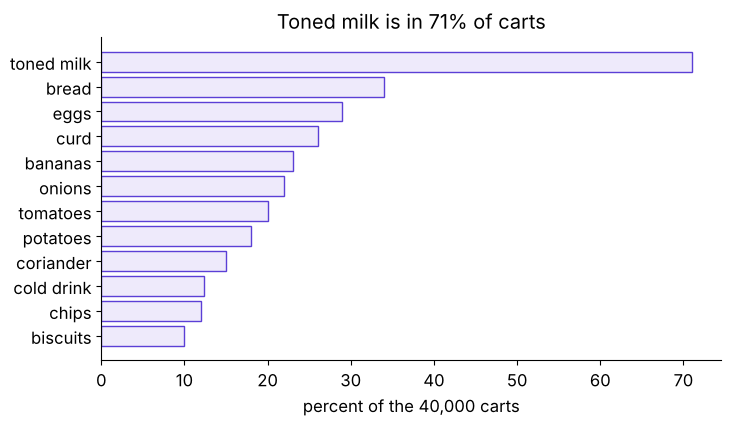

item
toned milk    0.710
bread         0.340
eggs          0.290
curd          0.260
bananas       0.230
onions        0.220
tomatoes      0.200
potatoes      0.180
coriander     0.150
cold drink    0.123
chips         0.120
biscuits      0.100
PASS milk is the most common item


In [2]:
share = items.groupby("item").cart_id.nunique().sort_values(ascending=False) / n
top = share.head(12)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index[::-1], top.values[::-1] * 100, color="#EEEAFB", edgecolor="#5B3FD6")
ax.set_xlabel("percent of the 40,000 carts")
ax.set_title(f"Toned milk is in {share['toned milk']:.0%} of carts")
plt.show()
print(share.head(12).round(3).to_string())
check("milk is the most common item", share.index[0] == "toned milk")

## Which pairs sit together most often?

The strip's new rule ranks by exactly this count. Every cart's items, taken two at a time,
add one to their pair's tally.

**Predict before you run.** Which pair is found together most often?

a) chips and cold drink
b) bread and toned milk
c) ice cream and chocolate sauce
d) onions and tomatoes

In [3]:
baskets = items.groupby("cart_id").item.apply(set)
pair_count = Counter(p for basket in baskets for p in combinations(sorted(basket), 2))
for (a, b), k in pair_count.most_common(6):
    print(f"{a} + {b}: {k:,} carts")
check("the most frequent pair holds milk", "toned milk" in pair_count.most_common(1)[0][0])

bread + toned milk: 10,064 carts
eggs + toned milk: 8,468 carts
curd + toned milk: 7,436 carts
bananas + toned milk: 6,624 carts
onions + toned milk: 6,248 carts
tomatoes + toned milk: 5,680 carts
PASS the most frequent pair holds milk


**What happened.** The answer is b, bread and milk in 10,064 carts, and
every one of the six most frequent pairs holds milk. **The plausible wrong answer** is "the
pairs table is the ranking": the most frequent partner of almost any item is milk, so a
strip ranked by count shows milk beside everything, which is what the strip did from
7 September. A count rewards the popular item, whatever it is paired with.

In [4]:
single = Counter(x for basket in baskets for x in basket)
table = pd.DataFrame([{"a": a, "b": b, "both": k, "support": k / n,
                       "conf_a_to_b": k / single[a], "conf_b_to_a": k / single[b],
                       "lift": k * n / (single[a] * single[b])}
                      for (a, b), k in pair_count.items()])
featured = [("bread", "toned milk"), ("eggs", "toned milk"), ("chips", "cold drink"),
            ("chocolate sauce", "ice cream")]
show = table.set_index(["a", "b"]).loc[featured].round(4)
print(show.to_string())
check("chips and cold drink: lift 3.39", round(show.loc[("chips", "cold drink"), "lift"], 2) == 3.39)

                             both  support  conf_a_to_b  conf_b_to_a    lift
a               b                                                           
bread           toned milk  10064   0.2516       0.7400       0.3544  1.0423
eggs            toned milk   8468   0.2117       0.7300       0.2982  1.0282
chips           cold drink   2000   0.0500       0.4167       0.4065  3.3875
chocolate sauce ice cream     100   0.0025       0.1838       0.0625  4.5956
PASS chips and cold drink: lift 3.39


## What does lift say about bread and milk that confidence does not?

Bread to milk reads confidence 0.74 on 40,000 carts. On the twelve
carts lift read 1.50, because all four bread carts happened to hold
milk; on 40,000 carts it reads 1.04, which says milk sits beside bread
about as often as it sits in any cart. The picture draws lift as two areas: bread's share
times milk's share is the overlap chance would give; the overlap seen is barely bigger.

bread 0.34 x milk 0.71 = 0.241 expected; seen 0.252; lift 1.04


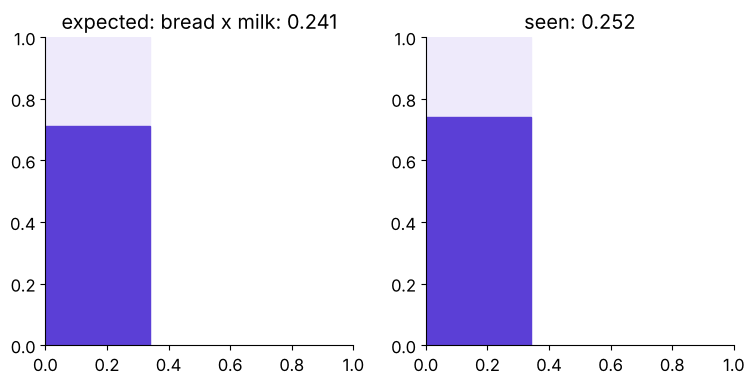

PASS bread to milk: confidence 0.74, lift 1.04


In [5]:
b, m = single["bread"] / n, single["toned milk"] / n
seen = pair_count[("bread", "toned milk")] / n
print(f"bread {b:.2f} x milk {m:.2f} = {b * m:.3f} expected; seen {seen:.3f}; lift {seen / (b * m):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, height, title in [(axes[0], m, "expected: bread x milk"), (axes[1], seen / b, "seen")]:
    ax.add_patch(plt.Rectangle((0, 0), b, 1, color="#EEEAFB"))
    ax.add_patch(plt.Rectangle((0, 0), b, height, color="#5B3FD6"))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_title(f"{title}: {b * height:.3f}")
plt.show()
check("bread to milk: confidence 0.74, lift 1.04", round(seen / b, 2) == 0.74 and round(seen / (b * m), 2) == 1.04)

## Does every popular item look bundled with milk?

**Predict before you run.** For the 50 items found in at least 2 percent
of carts, what does their lift with milk look like?

a) It rises with the item's popularity.
b) It sits near one for all of them.
c) It falls with the item's popularity.
d) It scatters, each item its own way.

50 items: confidence to milk 0.70 to 0.74, lift 0.99 to 1.04


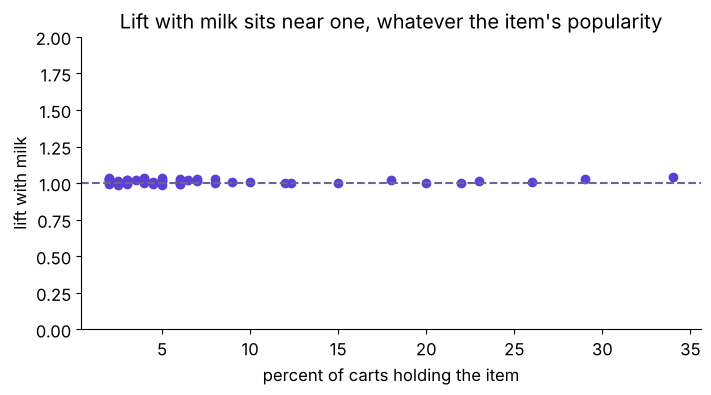

PASS every common item's lift with milk sits between 0.96 and 1.08


In [6]:
common = share[(share >= 0.02) & (share.index != "toned milk")].index
conf_milk = pd.Series({x: pair_count[tuple(sorted((x, "toned milk")))] / single[x] for x in common})
lift_milk = conf_milk / share["toned milk"]
print(f"{len(common)} items: confidence to milk {conf_milk.min():.2f} to {conf_milk.max():.2f}, "
      f"lift {lift_milk.min():.2f} to {lift_milk.max():.2f}")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(share[common] * 100, lift_milk, color="#5B3FD6")
ax.axhline(1, color="#6B6690", ls="--")
ax.set_ylim(0, 2); ax.set_xlabel("percent of carts holding the item"); ax.set_ylabel("lift with milk")
ax.set_title("Lift with milk sits near one, whatever the item's popularity")
plt.show()
check("every common item's lift with milk sits between 0.96 and 1.08", lift_milk.between(0.96, 1.08).all())

**What happened.** The answer is b. Confidence toward milk sits near milk's own share for
every item, because most carts hold milk whatever else they hold, and lift divides that
share out. Amazon met the same trap: counting how often buyers of A also bought B would
have made the bestseller the top recommendation beside everything, and the fix compares
with what chance predicts, which is lift in spirit (Amazon Science, checked 12 October
2026).

## Why did the strip's click-through fall from 6.1 percent to 3.8 percent?

`strip_log` counts each day's impressions (times a slot was shown), clicks and adds, by
slot, by the anchor item a suggestion was ranked from, and by the suggested item. Every
cart-page view shows all three slots. The strip shows packs, and toned milk comes in more
than one pack, so one view can show milk in two slots; the log names every pack by its item.

**Predict before you run.** Which explanation will the log support?

a) Shoppers' habits changed after the monsoon.
b) Fewer people opened the cart page in September.
c) Milk now fills the slots and is rarely clicked.
d) The strip sits lower on the page than it did.

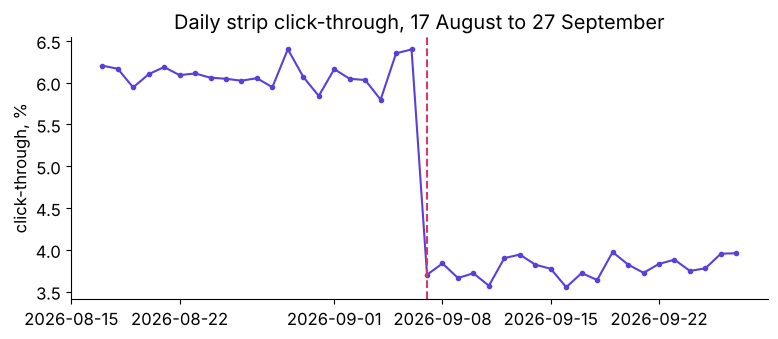

after
before    0.0610
after     0.0379
PASS 6.1 percent before, 3.8 after


In [7]:
log = pd.read_csv("../data/C2_W04_D03_strip_log_STUDENT.csv", parse_dates=["date"])
log["after"] = log.date >= "2026-09-07"
day = log.groupby("date")[["impressions", "clicks"]].sum()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(day.index, day.clicks / day.impressions * 100, marker="o", ms=3, color="#5B3FD6")
ax.axvline(pd.Timestamp("2026-09-07"), color="#D63A6A", ls="--")
ax.set_ylabel("click-through, %"); ax.set_title("Daily strip click-through, 17 August to 27 September")
plt.show()
window = log.groupby("after")[["impressions", "clicks"]].sum()
print((window.clicks / window.impressions).round(4).rename({False: "before", True: "after"}).to_string())
check("6.1 percent before, 3.8 after", [round(x, 3) for x in window.clicks / window.impressions] == [0.061, 0.038])

### Your turn: which slots does the fall sit in?

Split the after-change rows by whether the slot suggested toned milk. For each group print
its share of impressions and its click-through (clicks over impressions), then check that
the two rates, weighted by their shares, give back the blended rate. Start from
`after = log[log.after]` and `after.suggested_item == "toned milk"`.

In [8]:
after = log[log.after]
is_milk = after.suggested_item == "toned milk"
part = after.groupby(is_milk)[["impressions", "clicks"]].sum()
ctr = part.clicks / part.impressions
weight = part.impressions / part.impressions.sum()
print(f"milk: {weight[True]:.0%} of impressions at {ctr[True]:.1%}; "
      f"everything else: {weight[False]:.0%} at {ctr[False]:.1%}")
print(f"weighted back together: {(ctr * weight).sum():.1%}")
check("milk slots click at 1.2 percent and the rest at 6.4", round(ctr[True], 3) == 0.012 and round(ctr[False], 3) == 0.064)
check("the two rates rebuild the blend", abs((ctr * weight).sum() - after.clicks.sum() / after.impressions.sum()) < 1e-12)

milk: 50% of impressions at 1.2%; everything else: 50% at 6.4%
weighted back together: 3.8%
PASS milk slots click at 1.2 percent and the rest at 6.4
PASS the two rates rebuild the blend


**What happened.** The answer is c. After the change milk filled half the slot
impressions and clicked at 1.2 percent; everything else clicked at
6.4 percent, a little above the 6.2 percent it drew before.
Half of 1.2 plus half of 6.4 is 3.8. **The plausible wrong answer** is "shoppers changed
after the monsoon", which would have the team wait or redesign the strip. **The check** is
the split by suggested item: the fall sits in the milk slots. **The fix** is to rank by
lift above a support floor, which chapter 3 builds.

In [9]:
# A second route to lift: confidence over the partner's base rate, read in both directions.
for a, b in [("bread", "toned milk"), ("chips", "cold drink"), ("coriander", "green chillies")]:
    row = table[(table.a == a) & (table.b == b)].iloc[0]
    one = row.conf_a_to_b / (single[b] / n)
    other = row.conf_b_to_a / (single[a] / n)
    print(f"{a} + {b}: {row.lift:.4f} = {one:.4f} = {other:.4f}")
    check(f"{a} and {b}: three routes agree", abs(row.lift - one) < 1e-9 and abs(row.lift - other) < 1e-9)

bread + toned milk: 1.0423 = 1.0423 = 1.0423
PASS bread and toned milk: three routes agree
chips + cold drink: 3.3875 = 3.3875 = 3.3875
PASS chips and cold drink: three routes agree
coriander + green chillies: 3.0000 = 3.0000 = 3.0000
PASS coriander and green chillies: three routes agree


## What did 40,000 carts answer?

- **How often is each item in a cart?** Milk 71 percent, bread
  34 percent, eggs 29 percent.
- **Which pairs sit together most often?** Pairs with milk, led by bread and milk in
  10,064 carts, which is why a strip ranked by count fills with milk.
- **What does lift say about milk?** Near one with every common item: bread
  1.04, eggs 1.03. Chips and cold drink read
  3.39.
- **Why did the click-through fall?** Milk took half the slot impressions at
  1.2 percent; the rest clicked at 6.4 percent.

**In the interview.** "Support, confidence, lift: which one cannot be fooled by
popularity?" Lift, because it divides by the partner's base rate; confidence toward milk
sits near milk's own 71 percent for every item.